In [1]:
import pandas as pd, numpy as np

df = pd.read_csv("../results/sweep_results.csv")
df["test_r2"] = pd.to_numeric(df["test_r2"], errors="coerce")
df["config"]  = df["arch"] + np.where(df["mode"] == "-", "", "_" + df["mode"].astype(str))

agg = (df.groupby("config")["test_r2"].agg(["mean", "std", "count"])
         .sort_values("mean", ascending=False).reset_index())
agg["pm"] = agg.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1)
agg.to_csv("../results/money_panel_table.csv", index=False)
print(agg[["config", "pm", "count"]].to_string(index=False))

     config            pm  count
GTN_shuffle 0.864 ± 0.003      3
   GTN_full 0.863 ± 0.002      3
   GTN_none 0.862 ± 0.003      3
 GTN_none11 0.860 ± 0.003      3
        GBT 0.786 ± 0.000      3
   GNN_full 0.757 ± 0.008      3
   GNN_none 0.756 ± 0.004      3
GNN_shuffle 0.756 ± 0.003      3
 GTN_random 0.690 ± 0.009      3


In [2]:
piv = df.pivot_table(index="seed", columns="config", values="test_r2")

def delta(a, b):
    d = (piv[a] - piv[b]).dropna()
    return d.mean(), d.std(ddof=1), len(d)

rows = [
    ("GTN earns keep (full − GBT)",       "GTN_full",    "GBT"),
    ("GTN earns keep (none − GBT)",       "GTN_none",    "GBT"),
    ("GNN vs GBT (full)",                 "GNN_full",    "GBT"),
    ("basin signal   (GTN full − shuf)",  "GTN_full",    "GTN_shuffle"),
    ("basin structure (GTN shuf − none)", "GTN_shuffle", "GTN_none"),
    ("basin signal   (GNN full − shuf)",  "GNN_full",    "GNN_shuffle"),
]
for name, a, b in rows:
    m, s, n = delta(a, b)
    print(f"{name:34s} Δ = {m:+.4f} ± {s:.4f}  (n={n})")

GTN earns keep (full − GBT)        Δ = +0.0774 ± 0.0020  (n=3)
GTN earns keep (none − GBT)        Δ = +0.0758 ± 0.0032  (n=3)
GNN vs GBT (full)                  Δ = -0.0287 ± 0.0079  (n=3)
basin signal   (GTN full − shuf)   Δ = -0.0011 ± 0.0013  (n=3)
basin structure (GTN shuf − none)  Δ = +0.0027 ± 0.0024  (n=3)
basin signal   (GNN full − shuf)   Δ = +0.0015 ± 0.0080  (n=3)


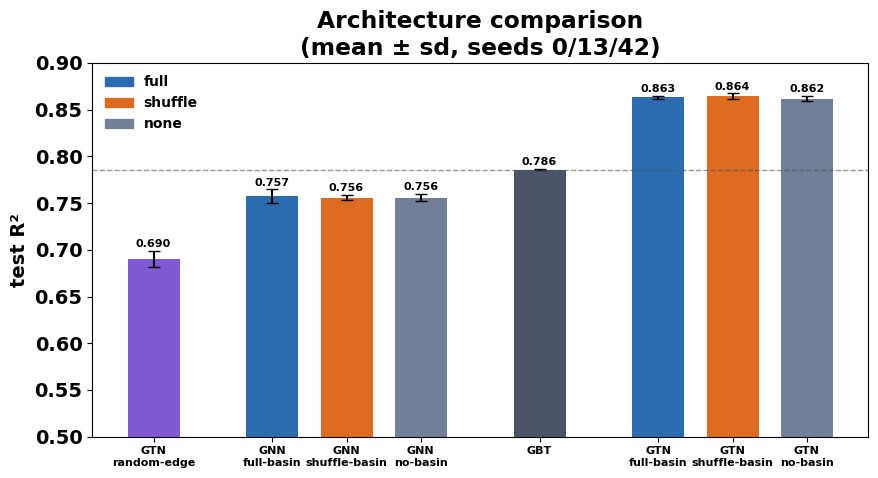

In [14]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Set global font size and bold weight
plt.rcParams.update({
    'font.size': 14,
    'font.weight': 'bold',
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
    'figure.titleweight': 'bold'
})

PANEL = [                              # append ("GTN","random",...) and feature-removal bars here later
    ("GTN", "random", "GTN\nrandom-edge"),
    ("GNN", "full",    "GNN\nfull-basin"),
    ("GNN", "shuffle", "GNN\nshuffle-basin"),
    ("GNN", "none",    "GNN\nno-basin"),
    ("GBT", "-",       "GBT"),
    ("GTN", "full",    "GTN\nfull-basin"),
    ("GTN", "shuffle", "GTN\nshuffle-basin"),
    ("GTN", "none",    "GTN\nno-basin"),    
]
CMAP = {"-":"#4a5568", "full":"#2b6cb0", "shuffle":"#dd6b20", "none":"#718096", "random":"#805ad5"}

def stat(arch, mode):
    s = df[(df["arch"] == arch) & (df["mode"] == mode)]["test_r2"]   # df["mode"], not df.mode
    return (s.mean(), s.std(ddof=1)) if len(s) else (np.nan, np.nan)

fig, ax = plt.subplots(figsize=(9, 5))
xs, x, prev = [], 0, None
for arch, mode, lab in PANEL:
    if prev and arch != prev: x += 0.6                 # gap between architecture groups
    m, s = stat(arch, mode); s = s if np.isfinite(s) else 0
    ax.bar(x, m, yerr=s, width=0.7, color=CMAP.get(mode, "#999"), capsize=4)
    ax.text(x, m + s + 0.004, f"{m:.3f}", ha="center", fontsize=8)
    xs.append((x, lab)); x += 1; prev = arch

ax.axhline(stat("GBT", "-")[0], ls="--", lw=1, color="#4a5568", alpha=0.6)
ax.set_xticks([p for p, _ in xs]); ax.set_xticklabels([l for _, l in xs], fontsize=8)
ax.set_ylabel("test R²")
ax.set_ylim(0.50, 0.90)
ax.set_title("Architecture comparison\n(mean ± sd, seeds 0/13/42)")
ax.legend(handles=[Patch(color=CMAP[m], label=m) for m in ["full","shuffle","none"]],
          frameon=False, loc="upper left", title_fontsize=10, fontsize=10)
plt.tight_layout()

plt.savefig("../figures/money_panel2010.png", dpi=200, bbox_inches="tight")

plt.show()